# Cumulative radiative response: background, land cover, and BVOCs

Regional net TOA radiative response of the future (2100, SSP5-8.5) forest expansion, built up step by step from CTRL_PD (supervisor's *Overview results.pdf*, P1 → P4). For each run, $R$ = net downward TOA flux `FSNT − FLNT`, annual mean over 2001–2014. Increments use paired years (nudged runs: year $y$ of one run against year $y$ of the other):

$$
\begin{aligned}
D_1 &= R(\mathrm{CTRL\_FUT})-R(\mathrm{CTRL\_PD}),\\
D_2 &= R(\mathrm{LCC\_FUT\_fBVOCctrlFUT})-R(\mathrm{CTRL\_FUT}),\\
D_3 &= R(\mathrm{LCC\_FUT})-R(\mathrm{LCC\_FUT\_fBVOCctrlFUT}),\\
T &= R(\mathrm{LCC\_FUT})-R(\mathrm{CTRL\_PD})=D_1+D_2+D_3.
\end{aligned}
$$

| Term | PDF step | Interpretation |
|---|---|---|
| D1 | P1 | Future background (climate, GHG, SST, emissions) at CTRL land cover; includes the climate-driven BVOC change |
| D2 | P2 − P1 | Biogeophysical (BGP) effect of the land-cover change, with BVOC emissions held at the CTRL_FUT climatology |
| D3 | P4 − P2 | BVOC-mediated effect of the new vegetation in the FUT climate (interactive MEGAN vs prescribed CTRL_FUT emissions) |
| T | P4 | Combined response |

The **cumulative bars** are D1, D1+D2 and T. Adjacent bar differences are D2 and D3. The attribution depends on this order; it is not a unique split into independent effects. P3 (BVOC from the new vegetation in the PD climate, `LCC_FUT_fBVOClccPD`), P5 (CO₂) and dO₃ need runs that do not exist yet.

### Runs and caveats
- **Current set:** CTRL `-20261023`, LCC `-20261005`, fBVOC `-20261025` (all 19 MEGAN species prescribed). All are on the **old spin-up chain**, so the numbers are provisional.
- **LCC_FUT and LCC_FUT_fBVOCctrlFUT** start from the FUT land spin-up that ran with pre-industrial CO₂ (CO₂ bug). **(a)** LCC and CTRL also had different land spin-ups. **(b)** Part of D2 can therefore come from the spin-up mismatch rather than from the forest change, also outside the modified cells.
- **D3** also contains the difference between a prescribed climatology (no interannual or weather coupling) and interactive emissions. MEGAN off removes all 19 species, so D3 is not ISOP + MTERP only.
- These are radiative **responses** (differences in TOA net flux between runs with different SSTs and GHGs), not effective radiative forcings. D1 is therefore much larger than D2 and D3.


## Setup
Inputs are the postprocessed monthly files `data/processed-data/postprocessing/<ALIAS>_atm_RADIATIVE_2001-2014.nc`. The first 12 months are already dropped as spin-up, the calendar is `noleap`, and time is the midpoint of `time_bnds`. Regions, masks and cell areas come from `boreal_forest_expansion.plotting.forcing_maps`, the same as in the other analysis notebooks.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

REPO_DIR = Path("/cluster/home/adelez/BOREAL-FOREST-EXPANSION")
sys.path.insert(0, str(REPO_DIR / "src"))
from boreal_forest_expansion.plotting.forcing_maps import POSTPROCESSED_DIR, cell_area, region_masks

plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 120})
CASES = ["CTRL_PD", "CTRL_FUT", "LCC_FUT_fBVOCctrlFUT", "LCC_FUT"]

### 1. Configuration
Annual means over 2001–2014 (14 years). Two regions: all cells ≥45°N, and the cells whose PFTs differ between LCC and CTRL (`modified cells`, land only). Both are area-weighted over all grid-cell area (ocean included for ≥45°N). Diagnostic: `FSNT − FLNT` (net downward SW minus outgoing LW at the model top). Positive = more energy into the system.

In [2]:
START_YEAR, END_YEAR = 2001, 2014
FILES = {case: POSTPROCESSED_DIR / f"{case}_atm_RADIATIVE_{START_YEAR}-{END_YEAR}.nc" for case in CASES}
PERIOD = (f"{START_YEAR}-01-01", f"{END_YEAR}-12-31")
MONTHS = list(range(1, 13))  # annual; use [6, 7, 8] for JJA
REGIONS = ["≥45°N", "modified cells"]
CONF = 0.95

SW_VAR, LW_VAR = "FSNT", "FLNT"
UNITS = "W m-2"
DIAGNOSTIC_LABEL = "Net downward TOA flux"

EXPORT = True
TABLE_PATH = REPO_DIR / "results" / "tables" / f"cumulative_radiative_decomposition_{START_YEAR}_{END_YEAR}.csv"
FIG_DIR = REPO_DIR / "results" / "figures" / "cumulative-radiative-decomposition"  # written only if EXPORT

### 2. Open the four runs and check the inputs
Before averaging, the cell below checks three things. Any failure raises an error.
- **Month labels:** each `time` lies inside its `time_bnds` and has the same month as the bound start. So the label is the month the mean represents, not the following month (the CAM month-end stamp).
- **Units:** `FSNT` and `FLNT` are in W/m2.
- **Sign:** `FSNT − FLNT` equals the postprocessed `NET_toa` ("net flux at top of model, down positive").

In [3]:
datasets, checks = {}, []
for case in CASES:
    if not FILES[case].exists():
        raise FileNotFoundError(FILES[case])
    ds = xr.open_dataset(FILES[case])
    t, tb = ds.time.values, ds.time_bnds.values
    inside = bool(np.all((tb[:, 0] <= t) & (t < tb[:, 1])))
    same_month = bool((ds.time_bnds.isel(nbnd=0).dt.month.values == ds.time.dt.month.values).all())
    units = {ds[v].attrs.get("units") for v in (SW_VAR, LW_VAR)}
    sign_err = float(abs(ds[SW_VAR] - ds[LW_VAR] - ds["NET_toa"]).max())
    checks.append({"Simulation": case, "File": FILES[case].name, "time in bounds": inside,
                   "month = bound month": same_month, "units": ", ".join(sorted(units)),
                   "max |FSNT−FLNT−NET_toa|": sign_err})
    if not (inside and same_month):
        raise ValueError(f"{case}: time labels do not match time_bnds")
    if units != {"W/m2"}:
        raise ValueError(f"{case}: unexpected units {units}")
    if sign_err > 1e-4:
        raise ValueError(f"{case}: FSNT - FLNT differs from NET_toa by {sign_err}")
    datasets[case] = ds
display(pd.DataFrame(checks))

,Simulation,File,time in bounds,month = bound month,units,max |FSNT−FLNT−NET_toa|
0,CTRL_PD,CTRL_PD_atm_RADIATIVE_2001-2014.nc,True,True,W/m2,0.0
1,CTRL_FUT,CTRL_FUT_atm_RADIATIVE_2001-2014.nc,True,True,W/m2,0.0
2,LCC_FUT_fBVOCctrlFUT,LCC_FUT_fBVOCctrlFUT_atm_RADIATIVE_2001-2014.nc,True,True,W/m2,0.0
3,LCC_FUT,LCC_FUT_atm_RADIATIVE_2001-2014.nc,True,True,W/m2,0.0


## Steps
### 3. Form the diagnostic and average in time
The period is selected before averaging. Monthly means are weighted by days per month, which gives one annual mean per year. Each selected year must contain all requested months; duplicated or missing months raise an error. The year/month sequence must match across runs, because the years are paired. A NaN at any selected time makes that cell unavailable.

In [4]:
def diagnostic(ds):
    a, b = xr.align(ds[SW_VAR], ds[LW_VAR], join="exact")
    field = a - b
    if set(field.dims) != {"time", "lat", "lon"}:
        raise ValueError(f"Expected time/lat/lon only; got {field.dims}")
    return field.transpose("time", "lat", "lon").astype("float64")

if not MONTHS or len(set(MONTHS)) != len(MONTHS) or not set(MONTHS) <= set(range(1, 13)):
    raise ValueError("MONTHS must contain unique month numbers 1–12.")
annual, records, signatures = {}, [], {}
for case, ds in datasets.items():
    field = diagnostic(ds).sel(time=slice(*PERIOD))
    field = field.sel(time=field.time.dt.month.isin(MONTHS))
    if field.sizes["time"] == 0:
        raise ValueError(f"{case}: empty time selection")
    years, months = field.time.dt.year.values, field.time.dt.month.values
    signature = list(zip(years.tolist(), months.tolist()))
    if len(set(signature)) != len(signature):
        raise ValueError(f"{case}: duplicate monthly labels or nonmonthly data")
    for year in np.unique(years):
        if set(months[years == year]) != set(MONTHS):
            raise ValueError(f"{case}: incomplete selected months in {year}")
    if set(years) != set(range(int(years.min()), int(years.max()) + 1)):
        raise ValueError(f"{case}: missing complete year")
    signatures[case] = sorted(signature)
    days = field.time.dt.days_in_month.astype(float)
    annual[case] = ((field * days).groupby("time.year").sum(skipna=False)
                    / days.groupby("time.year").sum())
    records.append({"Simulation": case, "First month": str(field.time.values[0]),
                    "Last month": str(field.time.values[-1]), "Years": len(np.unique(years)),
                    "Months": len(signature), "Calendar": str(field.time.dt.calendar)})
if any(value != signatures[CASES[0]] for value in signatures.values()):
    raise ValueError("Selected analysis months/years differ between simulations.")
if len({row["Calendar"] for row in records}) != 1:
    raise ValueError("Calendars differ; choose an explicit common temporal-weighting strategy first.")
aligned = xr.align(*(annual[case] for case in CASES), join="exact")
annual = xr.Dataset(dict(zip(CASES, aligned))).compute()  # (year, lat, lon) per run
display(pd.DataFrame(records))

,Simulation,First month,Last month,Years,Months,Calendar
0,CTRL_PD,2001-01-16 12:00:00,2014-12-16 12:00:00,14,168,noleap
1,CTRL_FUT,2001-01-16 12:00:00,2014-12-16 12:00:00,14,168,noleap
2,LCC_FUT_fBVOCctrlFUT,2001-01-16 12:00:00,2014-12-16 12:00:00,14,168,noleap
3,LCC_FUT,2001-01-16 12:00:00,2014-12-16 12:00:00,14,168,noleap


### 4. Use one spatial support and one set of weights
Weights are the real cell areas from the Gaussian weights `gw`, so the pole rows also get a positive weight. Masks come from `forcing_maps.region_masks`. `modified cells` = cells in `diagnostics/lcc-modified-cells/modified_cells.nc` with land fraction > 0. All four runs share the grid, and the cell below checks that exactly; there is no regridding.

In [5]:
template = annual[CASES[0]].isel(year=0, drop=True)
ref = datasets["CTRL_PD"]
for case in CASES[1:]:
    for coord in ["lat", "lon"]:
        if not np.array_equal(datasets[case][coord].values, ref[coord].values):
            raise ValueError(f"{case}: {coord} differs from CTRL_PD")
weights = cell_area(ref)
masks = region_masks(ref)
valid = np.isfinite(annual.to_array("simulation")).all(("simulation", "year"))

yearly, support = {}, []
for name in REGIONS:
    region = masks[name]
    if bool(((~np.isfinite(weights) | (weights <= 0)) & region).any()):
        raise ValueError(f"{name}: area weights must be finite and positive inside the region")
    base_weights = weights.where(region, 0)
    common_weights = base_weights.where(valid, 0)
    coverage = float(common_weights.sum()) / float(base_weights.sum())
    if coverage < 1 - 1e-10:
        raise ValueError(f"{name}: only {coverage:.2%} of the area has complete data in all runs")
    r = annual.where(region & valid).weighted(common_weights).mean(("lat", "lon"))
    yearly[name] = r.to_dataframe()[CASES]
    support.append({"Region": name, "Cells": int(region.sum()), "Area (10⁶ km²)": float(base_weights.sum()) / 1e12,
                    "Common coverage": f"{coverage:.2%}"})
display(pd.DataFrame(support))
means = pd.DataFrame({name: yearly[name].mean() for name in REGIONS})
means.index.name = f"Mean {START_YEAR}–{END_YEAR} ({UNITS})"
display(means.round(3))

,Region,Cells,Area (10⁶ km²),Common coverage
0,≥45°N,3456,73.212500,100.00%
1,modified cells,1152,28.877035,100.00%


,≥45°N,modified cells
Mean 2001–2014 (W m-2),,
CTRL_PD,-69.923,-76.407
CTRL_FUT,-68.939,-73.782
LCC_FUT_fBVOCctrlFUT,-68.769,-73.316
LCC_FUT,-68.738,-73.282


## Results
### 5. Calculate the increments and cumulative states
For each region and year, the increments come from adjacent runs, and the cumulative states come straight from each run minus CTRL_PD. The closure check compares these two routes. The interval is a 95 % t-interval across the 14 yearly values. It treats paired years as independent. It describes interannual noise and does not test significance against spin-up or chain differences.

In [6]:
STEPS = [("D1", "Future background", "CTRL_FUT", "CTRL_PD"),
         ("D2", "LCC, BVOCs fixed (BGP)", "LCC_FUT_fBVOCctrlFUT", "CTRL_FUT"),
         ("D3", "Additional BVOC", "LCC_FUT", "LCC_FUT_fBVOCctrlFUT"),
         ("T", "Total", "LCC_FUT", "CTRL_PD")]

def mean_ci(x):
    x = np.asarray(x, float)
    return x.mean(), stats.t.ppf(0.5 + CONF / 2, x.size - 1) * x.std(ddof=1) / np.sqrt(x.size)

rows, increments_by_year = [], {}
for name in REGIONS:
    y = yearly[name]
    inc = pd.DataFrame({key: y[c1] - y[c2] for key, _, c1, c2 in STEPS})
    cum = pd.DataFrame({case: y[case] - y["CTRL_PD"] for case in CASES[1:]})
    np.testing.assert_allclose(inc[["D1", "D2", "D3"]].cumsum(axis=1).values, cum.values, rtol=1e-10, atol=1e-10)
    np.testing.assert_allclose(inc[["D1", "D2", "D3"]].sum(axis=1), inc["T"], rtol=1e-10, atol=1e-10)
    print(f"{name}: closure residual {float((inc[['D1', 'D2', 'D3']].sum(axis=1) - inc['T']).abs().max()):.1e} {UNITS}")
    increments_by_year[name] = inc
    for (key, label, c1, c2), cum_case in zip(STEPS, CASES[1:] + ["LCC_FUT"]):
        m, h = mean_ci(inc[key])
        cm, ch = mean_ci(cum[cum_case])
        rows.append({"Region": name, "Term": key, "Step": label, "Contrast": f"{c1} − {c2}",
                     f"Increment ({UNITS})": m, "Increment ±CI95": h,
                     f"Cumulative vs CTRL_PD ({UNITS})": cm, "Cumulative ±CI95": ch, "Years": len(inc)})
results = pd.DataFrame(rows)
display(results.round(3))

≥45°N: closure residual 0.0e+00 W m-2
modified cells: closure residual 0.0e+00 W m-2


,Region,Term,Step,Contrast,Increment (W m-2),Increment ±CI95,Cumulative vs CTRL_PD (W m-2),Cumulative ±CI95,Years
0,≥45°N,D1,Future background,CTRL_FUT − CTRL_PD,0.984,0.180,0.984,0.180,14
1,≥45°N,D2,"LCC, BVOCs fixed (BGP)",LCC_FUT_fBVOCctrlFUT − CTRL_FUT,0.170,0.031,1.154,0.177,14
2,≥45°N,D3,Additional BVOC,LCC_FUT − LCC_FUT_fBVOCctrlFUT,0.031,0.040,1.185,0.176,14
3,≥45°N,T,Total,LCC_FUT − CTRL_PD,1.185,0.176,1.185,0.176,14
4,modified cells,D1,Future background,CTRL_FUT − CTRL_PD,2.625,0.284,2.625,0.284,14
5,modified cells,D2,"LCC, BVOCs fixed (BGP)",LCC_FUT_fBVOCctrlFUT − CTRL_FUT,0.466,0.034,3.091,0.286,14
6,modified cells,D3,Additional BVOC,LCC_FUT − LCC_FUT_fBVOCctrlFUT,0.034,0.057,3.125,0.267,14
7,modified cells,T,Total,LCC_FUT − CTRL_PD,3.125,0.267,3.125,0.267,14


### 6. Plot the cumulative story and the individual contributions
Left: each bar is a complete response relative to CTRL_PD (P1, P2, P4). Right: the individual increments, which sum to the total. Error bars are the 95 % interval across years. A negative increment reduces the cumulative response; it does not have to make the total negative.

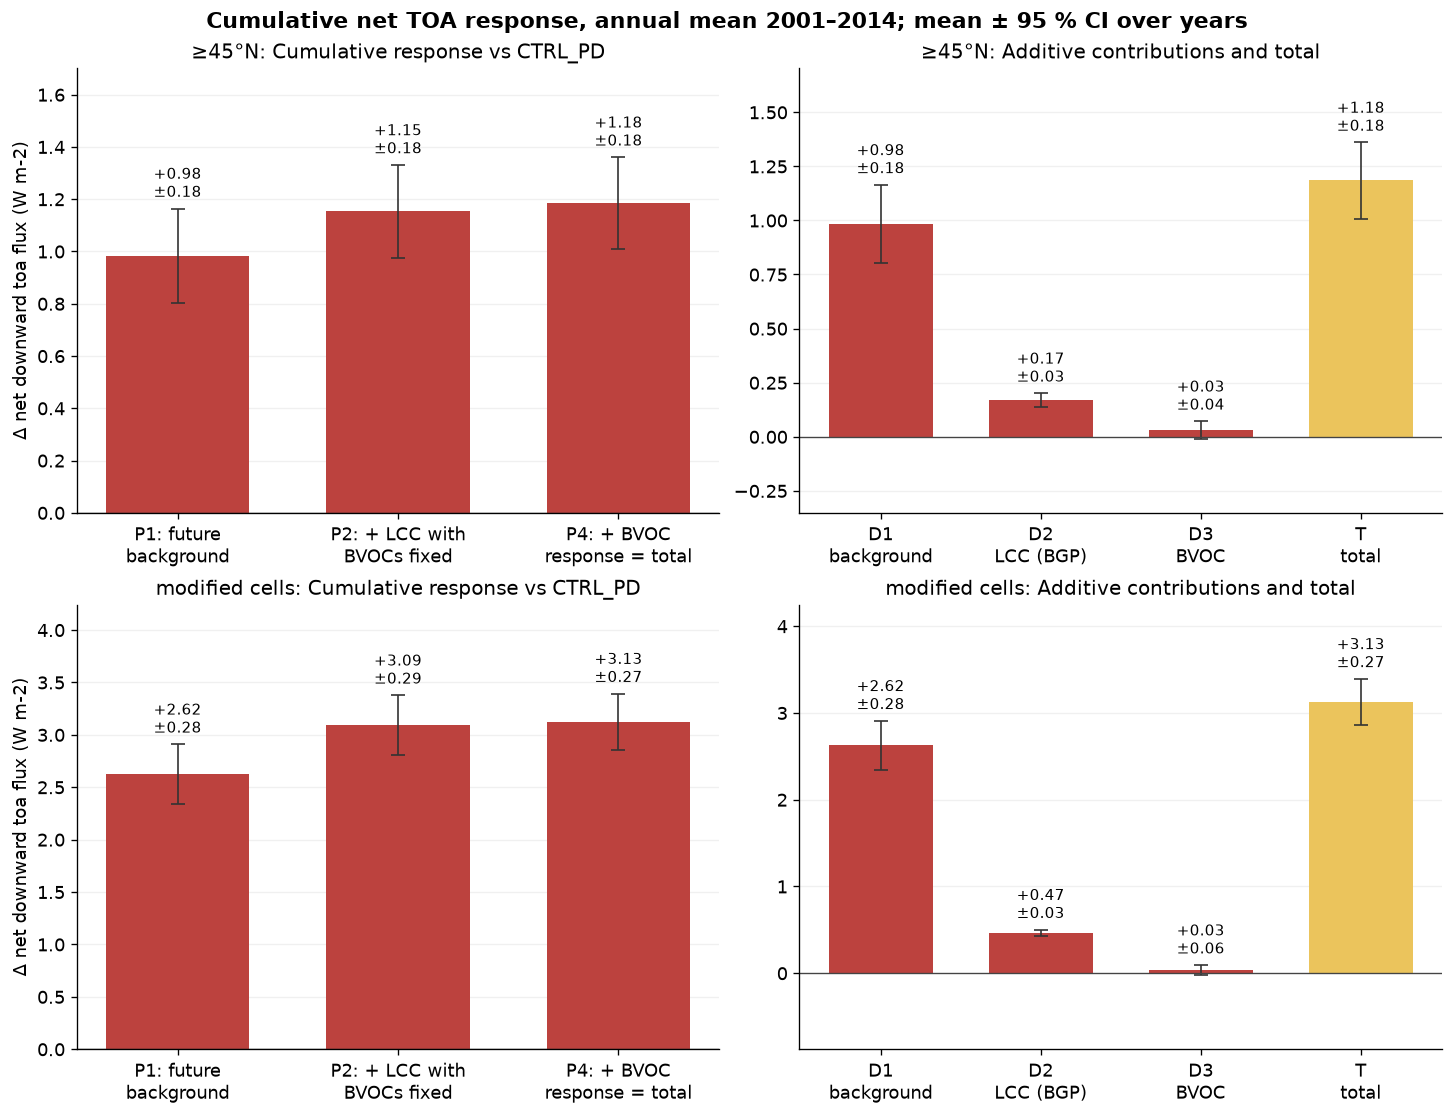

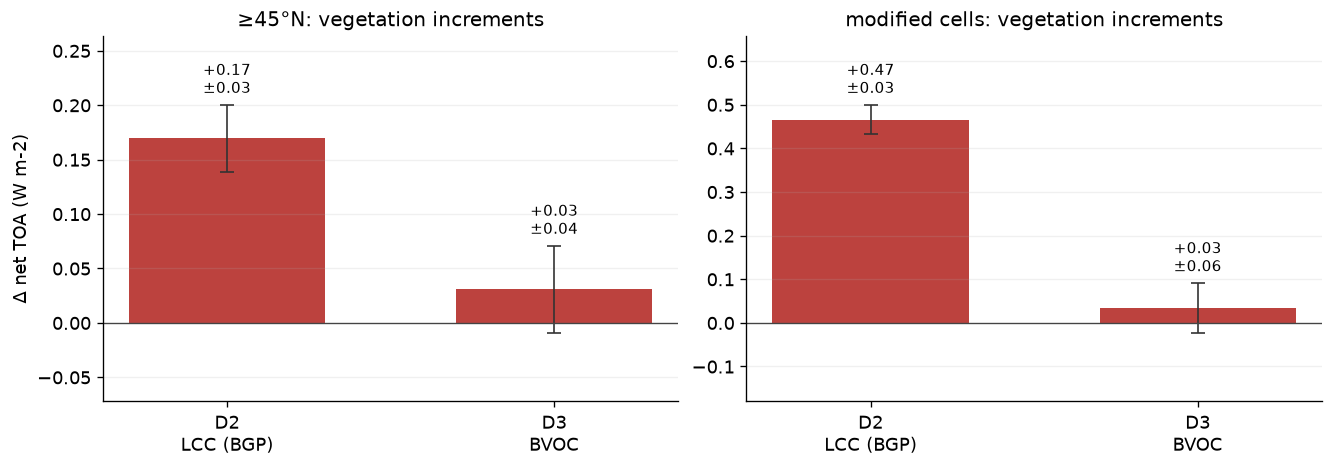

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/tables/cumulative_radiative_decomposition_2001_2014.csv
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/cumulative-radiative-decomposition/cumulative_radiative_decomposition_2001_2014.png
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/cumulative-radiative-decomposition/cumulative_radiative_decomposition_2001_2014_vegetation_increments.png


In [7]:
from boreal_forest_expansion.plotting import palette as pal   # project palette (2026-11-03)
cumulative_labels = ["P1: future\nbackground", "P2: + LCC with\nBVOCs fixed", "P4: + BVOC\nresponse = total"]
increment_labels = ["D1\nbackground", "D2\nLCC (BGP)", "D3\nBVOC", "T\ntotal"]
fig, axes = plt.subplots(len(REGIONS), 2, figsize=(12, 4.6 * len(REGIONS)), layout="constrained", squeeze=False)
for row, name in zip(axes, REGIONS):
    r = results[results.Region == name].set_index("Term")
    panels = [(r[f"Cumulative vs CTRL_PD ({UNITS})"].values[:3], r["Cumulative ±CI95"].values[:3], cumulative_labels,
               "Cumulative response vs CTRL_PD"),
              (r[f"Increment ({UNITS})"].values, r["Increment ±CI95"].values, increment_labels,
               "Additive contributions and total")]
    for ax, (values, half, ticklabels, title) in zip(row, panels):
        colors = [pal.RED if value >= 0 else pal.NAVY for value in values]   # warming red, cooling navy
        if ax is row[1]:
            colors[-1] = pal.TOTAL_COLOR   # total = gold
        bars = ax.bar(np.arange(len(values)), values, yerr=half, color=colors, width=0.65, capsize=4,
                      error_kw=dict(lw=1, ecolor="#333333"))
        ax.bar_label(bars, labels=[f"{v:+.2f}\n±{h:.2f}" for v, h in zip(values, half)], padding=4, fontsize=9)
        ax.set_xticks(np.arange(len(values)), ticklabels)
        ax.axhline(0, color="#444444", linewidth=0.8)
        ax.set_title(f"{name}: {title}", fontsize=12)
        ax.set_axisbelow(True)
        ax.grid(axis="y", alpha=0.18)
        ax.margins(y=0.25)
    row[0].set_ylabel(f"Δ {DIAGNOSTIC_LABEL.lower()} ({UNITS})")
fig.suptitle(f"Cumulative net TOA response, annual mean {START_YEAR}–{END_YEAR}; mean ± 95 % CI over years",
             fontsize=13, fontweight="bold")
plt.show()

# D2 and D3 are small next to D1: same increments on their own axis
fig2, axes2 = plt.subplots(1, len(REGIONS), figsize=(5.5 * len(REGIONS), 3.8), layout="constrained", squeeze=False)
for ax, name in zip(axes2[0], REGIONS):
    r = results[(results.Region == name) & results.Term.isin(["D2", "D3"])]
    values, half = r[f"Increment ({UNITS})"].values, r["Increment ±CI95"].values
    bars = ax.bar([0, 1], values, yerr=half, capsize=4, width=0.6,
                  color=[pal.RED if v >= 0 else pal.NAVY for v in values], error_kw=dict(lw=1, ecolor="#333333"))
    ax.bar_label(bars, labels=[f"{v:+.2f}\n±{h:.2f}" for v, h in zip(values, half)], padding=4, fontsize=9)
    ax.set_xticks([0, 1], increment_labels[1:3])
    ax.axhline(0, color="#444444", linewidth=0.8)
    ax.set_title(f"{name}: vegetation increments", fontsize=12)
    ax.grid(axis="y", alpha=0.18)
    ax.margins(y=0.3)
axes2[0, 0].set_ylabel(f"Δ net TOA ({UNITS})")
plt.show()

if EXPORT:
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    stem = f"cumulative_radiative_decomposition_{START_YEAR}_{END_YEAR}"
    results.to_csv(TABLE_PATH, index=False)
    fig.savefig(FIG_DIR / f"{stem}.png", dpi=200, bbox_inches="tight")
    fig2.savefig(FIG_DIR / f"{stem}_vegetation_increments.png", dpi=200, bbox_inches="tight")
    print(f"Saved {TABLE_PATH}\nSaved {FIG_DIR / (stem + '.png')}\nSaved {FIG_DIR / (stem + '_vegetation_increments.png')}")

## Checks and next steps
- The closure assertion checks the arithmetic only. It does not show that D1, D2 and D3 are physically independent, and it does not validate spin-up consistency.
- **Provisional:** these are old-chain runs (CO₂-bug FUT land spin-up, LCC vs CTRL spin-up mismatch). Rerun when the CO₂-fix chain (CTRL_FUT `-20261028`, LCC_FUT `-20261028`, new `LCC_FUT_fBVOCctrlFUT`) is archived and postprocessed. Also check the CO₂-fix chain on D2 outside the modified cells.
- **Missing PDF steps:** P3 (needs `LCC_FUT_fBVOClccPD`), P5 (CO₂) and dO₃ cannot be computed from the existing runs.
- **Season:** change `MONTHS` (e.g. `[6, 7, 8]`) and rerun from section 3. A pooled DJF does not assign December to the following season-year.
- For the split of each increment into Ghan terms (aerosol direct, cloud, clear-clean), see `forcing_maps.radiative_budget_table` / `radiative_forcing.ipynb`.

**Execution status:** see the saved outputs. Run with `$PY results/tables/logs/run_nb_inplace.py analysis/cumulative_radiative_decomposition.ipynb`.